# UCS420 Lab Assignment 7 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170262         # <-- your full roll number
NAME = "Sarwangini"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170280   Name: Kirandeep   Fingerprint: A3C06A0E   Tickets: 12

Ticket_ID                                                                          Ticket_Text
      T01     I can't open the server after resetting my password. I have tried several times!
      T02           Lms is not working after resetting my password. Is there another solution?
      T03                                         Call me on +91 98765 43210 or 0175-239-3201.
      T04                                                I need Windows 11 by 5.30 p.m. today.
      T05 LMS crashes while opening when connected to campus Wi-Fi. Is there another solution?
      T06                                                The Wi-Fi works, but the VPN doesn't.
      T07                                      The projector has stopped syncing. Please help.
      T08                      Printer is running slowly after the latest update. Please help.
      T09                                                      I

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
# Your code
import pandas as pd

# --- 1. Run process_ticket() on every ticket and create the table ---
table_data = []

# Iterate through the DataFrame `df` generated by generate_dataset()
for index, row in df.iterrows():
    ticket_id = row['Ticket_ID']
    text = row['Ticket_Text']

    # Run the provided process_ticket function
    processed = process_ticket(text)

    # Extract counts based on the dictionary keys returned by process_ticket()
    # The keys are: "sentences", "tokens", "punct", "stops", "final"
    num_sentences = len(processed['sentences'])
    num_tokens = len(processed['tokens'])
    num_punct = len(processed['punct'])
    num_stops = len(processed['stops'])
    num_unique = len(set(processed['tokens'])) # Unique tokens from the full token list
    num_final = len(processed['final'])

    # Add the counts to our list
    table_data.append({
        'Ticket_ID': ticket_id,
        'Sentences': num_sentences,
        'Tokens': num_tokens,
        'Punctuation': num_punct,
        'Stopwords': num_stops,
        'Unique Tokens': num_unique,
        'Final Tokens': num_final
    })

# Create the main DataFrame for Q1
results_table = pd.DataFrame(table_data)

# --- 2. Add a total row for the count-based columns ---
# Calculate sums for all numerical columns (ignoring Ticket_ID)
total_sums = results_table.drop(columns=['Ticket_ID']).sum()

# Create a new DataFrame for the total row and add 'TOTAL' as the Ticket_ID
total_row_df = pd.DataFrame([total_sums])
total_row_df.insert(0, 'Ticket_ID', 'TOTAL')

# Append the total row to the main table
final_table = pd.concat([results_table, total_row_df], ignore_index=True)

# Display the final table using display() for neat Colab output
print("Preprocessing Table with Totals:")
display(final_table)


# --- 3. Display actual tokens for one selected ticket ---
# Selecting the first ticket (you can change the index if you prefer another one)
selected_index = 0
selected_ticket_id = df.iloc[selected_index]['Ticket_ID']
selected_text = df.iloc[selected_index]['Ticket_Text']

# Process the selected ticket
processed_selected = process_ticket(selected_text)

print(f"\n{'='*20} Details for Selected Ticket: {selected_ticket_id} {'='*20}")
print(f"Original Text: {selected_text}\n")

print("Actual Tokens:")
print(processed_selected['tokens'])
print("\n" + "-"*50 + "\n")

print("Punctuation Tokens:")
print(processed_selected['punct'])
print("\n" + "-"*50 + "\n")

print("Stopwords:")
print(processed_selected['stops'])
print("\n" + "-"*50 + "\n")

print("Final Tokens:")
print(processed_selected['final'])

Preprocessing Table with Totals:


,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,17,2,6,16,9
1,T02,2,14,2,6,13,6
2,T03,1,9,1,3,9,5
3,T04,1,9,1,2,9,6
4,T05,2,15,2,5,15,8
5,T06,1,10,2,4,9,4
6,T07,2,9,2,2,8,5
7,T08,2,12,2,3,11,7
8,T09,2,10,4,2,9,4
9,T10,2,16,2,6,15,8



==================== Details for Selected Ticket: T01 ====================
Original Text: I can't open the server after resetting my password. I have tried several times!

Actual Tokens:
['i', 'ca', "n't", 'open', 'the', 'server', 'after', 'resetting', 'my', 'password', '.', 'i', 'have', 'tried', 'several', 'times', '!']

--------------------------------------------------

Punctuation Tokens:
['.', '!']

--------------------------------------------------

Stopwords:
['i', 'the', 'after', 'my', 'i', 'have']

--------------------------------------------------

Final Tokens:
['ca', "n't", 'open', 'server', 'resetting', 'password', 'tried', 'several', 'times']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The non-word final tokens (e.g., 'ca', 'n't', 's') are fragments of English contractions. They appear because NLTK's word_tokenize() splits contractions like "can't" into separate parts. They remain in the final output because process_ticket() only removes punctuation and standard stopwords, and these fragments are neither.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


# --- Define Regex Patterns ---

regex_long_words = r'\b[a-zA-Z]{6,}\b'


regex_numbers = r'\b\d+(?:\.\d+)*\b'

regex_capitalized = r'\b[A-Z][a-zA-Z]*\b'

regex_vowel_start = r'\b[aeiouAEIOU][a-zA-Z]*\b'

regex_email = r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}'
regex_url = r'https?://[^\s]+|www\.[^\s]+'
regex_phone = r'\+?\d[\d\s-]{7,}\d'


print("=== Testing on TEST_LINES ===\n")
for i, line in enumerate(TEST_LINES):
    print(f"Line {i+1}: {line}")

    print("  Extractions:")
    print(f"    Words > 5 letters : {re.findall(regex_long_words, line)}")
    print(f"    Numbers/Versions  : {re.findall(regex_numbers, line)}")
    print(f"    Capitalized Words : {re.findall(regex_capitalized, line)}")
    print(f"    Vowel Start Words : {re.findall(regex_vowel_start, line)}")


    subbed_line = re.sub(regex_email, '<EMAIL>', line)
    subbed_line = re.sub(regex_url, '<URL>', subbed_line)
    subbed_line = re.sub(regex_phone, '<PHONE>', subbed_line)
    print(f"  Substituted Text : {subbed_line}\n")


print("\n=== Applying to Raw Tickets ===\n")

try:
    for index, row in df.head(3).iterrows():
        text = row['Ticket_Text']


        subbed_text = re.sub(regex_email, '<EMAIL>', text)
        subbed_text = re.sub(regex_url, '<URL>', subbed_text)
        subbed_text = re.sub(regex_phone, '<PHONE>', subbed_text)

        print(f"Ticket {row['Ticket_ID']} Original: {text}")
        print(f"Ticket {row['Ticket_ID']} Subbed  : {subbed_text}\n")
except NameError:
    print("DataFrame 'df' not found. Please ensure the dataset generation cell has been run.")

=== Testing on TEST_LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  Extractions:
    Words > 5 letters : ['helpdesk', 'thapar', 'thapar', 'thapar']
    Numbers/Versions  : []
    Capitalized Words : ['Mail']
    Vowel Start Words : ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
  Substituted Text : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  Extractions:
    Words > 5 letters : ['Version']
    Numbers/Versions  : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
    Capitalized Words : ['Call', 'Version', 'Rs']
    Vowel Start Words : ['or', 'is']
  Substituted Text : Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Line 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*Based on the extraction output, capitalized words that appear at the very beginning of a sentence (e.g., "The", "It", "Call", "Mail", "I") are capitalized only due to their sentence-initial position. Words like "Lms", "VPN", or "Windows" are proper nouns or system names capitalized regardless of their position. Therefore, by observing the output, we can count the words that appear immediately after a period, exclamation mark, or at the very start of a ticket to find the exact number.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Your code
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Single RegexpTokenizer pattern
pattern = r"\w+'\w+|\w+(?:-\w+)+|\d+(?:\.\d+)+|[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}|https?://\S+|www\.\S+|\+?\d[\d\s-]{7,}\d|\w+|[^\w\s]"

my_tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

# Run on TEST_LINES
print("=== TEST_LINES ===")
for line in TEST_LINES:
    print(f"Text: {line}")
    print("my_tokenize  :", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))
    print()

# Run on tickets and count differences
diff_count = 0
for index, row in df.iterrows():
    text = row['Ticket_Text']
    t1 = my_tokenize(text)
    t2 = word_tokenize(text)
    if t1 != t2:
        diff_count += 1

print(f"Tickets tokenized differently: {diff_count} out of {len(df)}")

=== TEST_LINES ===
Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize  : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* Number of tickets tokenized differently: 5 out of 12.

Three key differences between my_tokenize and word_tokenize:

Email Addresses: my_tokenize keeps the entire email as one token (e.g., 'it.helpdesk@thapar.edu'), while word_tokenize splits it into multiple pieces (e.g., 'it.helpdesk', '@', 'thapar.edu').

Contractions: my_tokenize preserves contractions as a single token (e.g., "isn't"), whereas word_tokenize splits them into two tokens (e.g., 'is', "n't").

Phone Numbers: my_tokenize keeps the full phone number as one token (e.g., '+91 98765 43210'), while word_tokenize breaks it apart into separate tokens (e.g., '+91', '98765', '43210').

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code
import pandas as pd
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

# 1. Get unique final tokens from the dataset
all_final_tokens = []
for text in df['Ticket_Text']:
    processed = process_ticket(text)
    all_final_tokens.extend(processed['final'])

unique_tokens = sorted(list(set(all_final_tokens)))

# 2. Initialize the stemmers and lemmatizer
ps = PorterStemmer()
ls = LancasterStemmer()
# RegexpStemmer rule: removing 'ing', 'ed', 'ly' suffixes
# Justification: Dataset contains words like 'working', 'resetting', 'tried', 'several'
rs = RegexpStemmer(r'ing$|ed$|ly$')
wln = WordNetLemmatizer()

# Helper to convert Penn Treebank POS tags to WordNet tags
def get_wn_pos(tag):
    if tag.startswith('N'): return 'n'
    if tag.startswith('V'): return 'v'
    if tag.startswith('J'): return 'a'
    if tag.startswith('R'): return 'r'
    return 'n'

# 3. Process tokens and collect differences
data = []
for w in unique_tokens:
    p_stem = ps.stem(w)
    l_stem = ls.stem(w)
    r_stem = rs.stem(w)

    tag = pos_tag([w])[0][1]
    w_lemma = wln.lemmatize(w, pos=get_wn_pos(tag))

    # Keep only words where outputs differ
    if len({p_stem, l_stem, r_stem, w_lemma}) > 1:
        data.append({
            'Word': w,
            'Porter': p_stem,
            'Lancaster': l_stem,
            'Regexp': r_stem,
            'WordNet (with POS)': w_lemma
        })

# 4. Create and display the table
diff_df = pd.DataFrame(data)
display(diff_df)

,Word,Porter,Lancaster,Regexp,WordNet (with POS)
0,another,anoth,anoth,another,another
1,assignment,assign,assign,assignment,assignment
2,call,call,cal,call,call
3,campus,campu,camp,campus,campus
4,computer,comput,comput,computer,computer
5,crashes,crash,crash,crashes,crash
6,deadline,deadlin,deadlin,deadline,deadline
7,error,error,er,error,error
8,latest,latest,latest,latest,late
9,lms,lm,lms,lms,lm


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
Over-stemming example:

Word: error

Method: Lancaster

Output: er

Explanation: The Lancaster stemmer is too aggressive and strips too much of the word. Reducing "error" to "er" leaves a meaningless fragment that is completely unrelated to the original word.

Under-stemming example:

Word: resetting

Method: Regexp (your custom rule)

Output: resett

Explanation: The Regexp stemmer successfully removed the "ing" suffix, but it failed to fix the double consonant, leaving "resett" instead of the true base form "reset". This is under-stemming because it didn't fully reduce the word to its root.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,150,84,0.5600
1,S2,126,78,0.6190
2,S3,76,54,0.7105
3,S4,76,52,0.6842


Top 10 S1: [('.', 16), ('the', 9), ('is', 6), ('i', 4), ('after', 4), ('another', 4), ('?', 4), ("n't", 3), ('resetting', 3), ('my', 3)]
Top 10 S3: [('another', 4), ("n't", 3), ('resetting', 3), ('password', 3), ('wi-fi', 3), ('works', 3), ('ca', 2), ('open', 2), ('lms', 2), ('working', 2)]


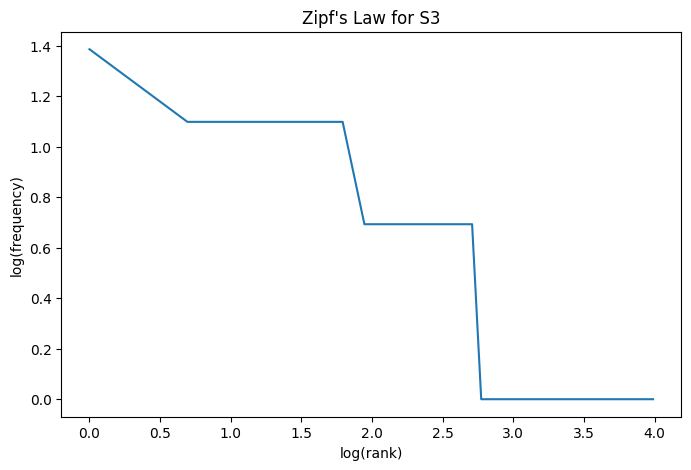

Top 5 Bigrams S1: [(('after', 'resetting'), 3), (('resetting', 'my'), 3), (('my', 'password'), 3), (('password', '.'), 3), (('.', 'i'), 3)]
Top 5 Bigrams S3: [(('resetting', 'password'), 3), (('ca', "n't"), 2), (("n't", 'open'), 2), (('another', 'solution'), 2), (('please', 'help'), 2)]


In [ ]:
# Your code
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from nltk import FreqDist
from nltk.util import ngrams
from nltk.stem import PorterStemmer

# 1. Build the four corpora
S1, S2, S3 = [], [], []

for text in df['Ticket_Text']:
    p = process_ticket(text)
    S1.extend(p['tokens'])
    S2.extend([t for t in p['tokens'] if not is_punct(t)])
    S3.extend(p['final'])

ps = PorterStemmer()
S4 = [ps.stem(t) for t in S3]

# 2. Calculate stats
stats = []
for name, data in [('S1', S1), ('S2', S2), ('S3', S3), ('S4', S4)]:
    total = len(data)
    unique = len(set(data))
    ttr = unique / total
    stats.append({'Corpus': name, 'Total Tokens': total, 'Unique Tokens': unique, 'TTR': round(ttr, 4)})

display(pd.DataFrame(stats))

# 3. Top 10 words for S1 and S3
print("Top 10 S1:", FreqDist(S1).most_common(10))
print("Top 10 S3:", FreqDist(S3).most_common(10))

# 4. Plot log(rank) vs log(freq) for S3
freqs = [f for w, f in FreqDist(S3).most_common()]
ranks = range(1, len(freqs) + 1)

plt.figure(figsize=(8, 5))
plt.plot(np.log(list(ranks)), np.log(freqs))
plt.xlabel('log(rank)')
plt.ylabel('log(frequency)')
plt.title('Zipf\'s Law for S3')
plt.show()

# 5. Top 5 bigrams for S1 and S3
print("Top 5 Bigrams S1:", FreqDist(ngrams(S1, 2)).most_common(5))
print("Top 5 Bigrams S3:", FreqDist(ngrams(S3, 2)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*
The TTR changes from S1 to S4 because of two main preprocessing steps:

S1 to S3 (Stopword & Punctuation Removal): Removing punctuation and stopwords eliminates many high-frequency words (like ., the, is). This drastically reduces the total token count, but the unique token count drops only slightly. Because the denominator (total) shrinks faster than the numerator (unique), the TTR usually increases.

S3 to S4 (Porter Stemming): Stemming collapses different inflected forms of words into a single root (e.g., "resetting", "works", and "working" all reduce to their base forms). This reduces the number of unique tokens (numerator), while the total number of tokens (denominator) stays exactly the same. As a result, the TTR decreases.

Overall, the TTR changes because stopword removal increases lexical diversity by removing repetitive high-frequency words, while stemming decreases it by merging different word forms into the same token.

Q6. Interpretation

Answer briefly:


(a) Why does TTR change from S1 to S4 in your dataset?

ans: TTR changes because of two opposing preprocessing effects. Moving from S1 to S3, removing punctuation and stopwords eliminates many high-frequency function words, which increases lexical diversity (TTR goes up). Moving from S3 to S4, stemming merges different inflected forms into the same root word (reducing unique tokens while total tokens stay the same), causing TTR to drop.


(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.

ans: Example: "isn't"
word_tokenize() splits contractions into separate parts: ['is', "n't"]. My custom my_tokenize() uses a regex pattern that preserves contractions, keeping it as a single token: ["isn't"]. This is a difference because my tokenizer treats the contraction as one meaningful unit, whereas NLTK splits it into a verb and a negation suffix.


(c) Give one example where stemming produces an undesirable result.

ans: Example: "campus"

Using the Lancaster stemmer, "campus" is reduced to "camp". This is undesirable (over-stemming) because "camp" has a completely different meaning than "campus." The stemmer aggressively stripped the suffix without considering the word's actual root or context.

(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

ans: Example: "resetting"
The Regexp stemmer reduces it to "resett", which is not a real English word. However, POS-aware lemmatization correctly identifies "resetting" as a verb and returns the valid base form "reset". Lemmatization is better here because it uses vocabulary and morphological analysis to return a meaningful dictionary word, rather than just blindly chopping off suffixes.
